# Clasificación del ICVU por comuna con KNN
Descripción breve, objetivo, versión y autores.

## 0. Configuración
Librerías, parámetros globales y rutas (`raiz_proyecto()`).

## 1. Obtención de datos
Los datos se generan en `01_Obtención.ipynb` (descarga OSM, toma varios minutos).
Aquí solo se carga `dataset/raw/dataset_comunas.csv`.

## 2. Limpieza y validación
Qué se revisa, qué se corrige y qué se deja para el Pipeline (y por qué).
Salida: `dataset/processed/dataset_limpio.csv`.

## 3. Análisis exploratorio (EDA)
### 3.1 Variable objetivo
### 3.2 Distribuciones y sesgo
### 3.3 Outliers
### 3.4 Relación con el ICVU
### 3.5 Redundancia entre variables
### 3.6 Conclusiones del EDA

## 4. Modelos
### 4.1 Selección de variables
### 4.2 KNN clasificación
### 4.3 KNN regresión
### 4.4 Comparación y conclusiones

## 5. Limitaciones
(sesgo de OSM hacia comunas ricas, solo 42 comunas, etc.)

# 1. Obtención de datos 
Descarga desde OpenStreetMap los equipamientos (salud, educación, transporte, etc.) de **varias comunas** y construye un dataset con **una fila por comuna**, listo para unirlo con el ICVU y entrenar el modelo.

v1.0 · 18-10-2026

**Cambios respecto de `data_obtain_test.ipynb`**

| Problema | Corrección |
|---|---|
| Solo una comuna (1 fila de ICVU) | Ciclo sobre `COMUNAS`, con caché por comuna (si se corta, se retoma donde quedó) |
| Paraderos contados 2 veces (`Paradero_bus` + `Paradero_plataforma`) y estaciones 2 veces (`Metro_estacion` + `Metro_railway`) | Cada objeto OSM se cuenta **una sola vez por categoría** (gana el primer tipo de la lista) |
| `Metro_railway` incluía el funicular | Renombrado a `Tren_estacion`: solo estaciones de tren (EFE, Metrotren), sin funicular ni metro |
| `Centro_salud` = 0 (los CESFAM están etiquetados como clínica/hospital) | Regla por nombre: CESFAM, CECOSF, SAPU, SAR, SUR, COSAM → `Centro_salud` |
| Mismo lugar mapeado como punto y como polígono | Se elimina el duplicado si tiene el mismo nombre y está a < 30 m |
| Parques y zonas contados como "1" sin importar su tamaño | Se calcula el **área** (m²) y el % de la comuna cubierto (`pct_area_*`) |
| Efecto borde (lo que está al otro lado de la calle no cuenta) | Descarga con un margen `BUFFER_M`; columna `dentro_comuna` para distinguir |
| CSV con 220 columnas de etiquetas OSM | Se guardan solo las columnas útiles |
| Conteos sin normalizar | Densidad por km² y, si se entrega población, por 10.000 hab |

> **Nota sobre sesgo:** OSM suele estar más completo en comunas de mayores ingresos, y eso se correlaciona con el ICVU. Hay que mencionarlo como limitación en el informe.

## 1.1 Librerías
La celda siguiente instala lo necesario en el kernel actual (solo hace falta la primera vez).

In [37]:
%pip install -q pandas geopandas osmnx matplotlib

Note: you may need to restart the kernel to use updated packages.


In [38]:
import re
import time
import unicodedata
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

## 1.2 Parámetros

In [39]:
DEBUG = True

# --- Comunas a descargar (editar libremente) ---------------------------------
# Las 42 comunas de la Región Metropolitana que mide el ICVU 2025 (CChC / Estudios Urbanos UC),
# con su nivel publicado (solo como referencia; el modelo usa el puntaje numérico).
# Para una prueba rápida: COMUNAS = ["Providencia", "Maipú", "Pudahuel"]
NIVEL_ICVU_2025 = {
    # Alto
    "Las Condes": "Alto", "Vitacura": "Alto", "Providencia": "Alto", "Ñuñoa": "Alto",
    "Lo Barnechea": "Alto", "La Reina": "Alto", "Santiago": "Alto", "San Miguel": "Alto",
    "Huechuraba": "Alto",
    # Medio alto
    "Colina": "Medio alto", "Maipú": "Medio alto", "Peñalolén": "Medio alto",
    "Independencia": "Medio alto", "La Cisterna": "Medio alto", "Recoleta": "Medio alto",
    "Estación Central": "Medio alto",
    # Medio bajo
    "Macul": "Medio bajo", "La Florida": "Medio bajo", "Pudahuel": "Medio bajo",
    "Cerrillos": "Medio bajo", "Quinta Normal": "Medio bajo", "San Joaquín": "Medio bajo",
    "Peñaflor": "Medio bajo", "Quilicura": "Medio bajo", "Puente Alto": "Medio bajo",
    "Lampa": "Medio bajo", "Renca": "Medio bajo", "Buin": "Medio bajo",
    "San Bernardo": "Medio bajo",
    # Bajo
    "Paine": "Bajo", "Conchalí": "Bajo", "Lo Prado": "Bajo", "Padre Hurtado": "Bajo",
    "Pedro Aguirre Cerda": "Bajo", "La Granja": "Bajo", "El Bosque": "Bajo",
    "La Pintana": "Bajo", "Melipilla": "Bajo", "Lo Espejo": "Bajo", "San Ramón": "Bajo",
    "Cerro Navia": "Bajo", "Talagante": "Bajo",
}
COMUNAS = list(NIVEL_ICVU_2025)

# Texto que se agrega al nombre para geocodificar en Nominatim
SUFIJO_CONSULTA = ", Región Metropolitana de Santiago, Chile"
# Consultas especiales cuando el nombre es ambiguo (revisar el mapa de límites más abajo).
# "R<número>" = relación exacta de OpenStreetMap (búsquela en nominatim.openstreetmap.org)
CONSULTA_ESPECIAL = {
    "Santiago": "Santiago, Provincia de Santiago, Región Metropolitana de Santiago, Chile",
    "Talagante": "R1626706",   # por nombre se obtenía la Provincia de Talagante (581 km²)
}
AREA_MAX_KM2 = 1800   # una comuna más grande que esto = se geocodificó otra cosa (región, provincia)

# --- Descarga ------------------------------------------------------------------
BUFFER_M = 500             # margen alrededor de la comuna (efecto borde). 0 = sin margen
CONTAR_CON_BUFFER = True   # True: los conteos incluyen el margen; False: solo dentro de la comuna
MARGEN_DESCARGA_M = 100         # la zona de descarga se amplía y simplifica para que la
TOLERANCIA_SIMPLIFICAR_M = 50   # consulta a Overpass no sea demasiado grande (error 413)
REINTENTOS = 3
# Servidores Overpass: si el principal está saturado se prueba el siguiente
# (se reordena solo: el último que funcionó se prueba primero)
OVERPASS_URLS = [
    "https://maps.mail.ru/osm/tools/overpass/api",   # VK Maps
    "https://overpass-api.de/api",                    # principal (FOSSGIS), suele estar saturado
    "https://overpass.private.coffee/api",
]
ARCHIVO_LOG = "descarga_log.txt"   # registro del avance de la descarga
PAUSA_ENTRE_COMUNAS_S = 5  # cortesía con el servidor Overpass

ox.settings.use_cache = True
ox.settings.requests_timeout = 300

# --- Archivos ------------------------------------------------------------------
CARPETA_CACHE = Path("datos_comunas")        # un .gpkg por comuna (permite retomar)
SALIDA_GPKG = "features_comunas.gpkg"        # todos los puntos + límites
SALIDA_CSV = "features_comunas.csv"          # todos los puntos (sin geometría)
SALIDA_RESUMEN = "resumen_conteos.csv"       # conteos comuna × tipo (formato largo)
SALIDA_DATASET = "dataset_comunas.csv"       # UNA FILA POR COMUNA -> entrada del modelo

ARCHIVO_POBLACION = "poblacion_comunas.csv"  # opcional: columnas comuna,poblacion (Censo 2024)
ARCHIVO_ICVU = "icvu_comunas.csv"            # columnas comuna,nivel_2025,ICVU_nivel. Si no existe, se crea

CRS_GEO = "EPSG:4326"
CRS_METRICO = 32719   # UTM 19S, metros (Santiago)

# --- Categorías y tipos (mismas variables que la versión anterior) --------------
categorias = {
    "Salud": {
        "Hospital":        {"amenity": "hospital"},
        "Clinica":         {"amenity": "clinic"},
        "Centro_salud":    {"healthcare": "centre"},          # + regla por nombre (CESFAM, etc.)
        "Consultorio":     {"amenity": "doctors"},
        "Farmacia":        {"amenity": "pharmacy"},
    },
    "Recreativo_Cultural": {
        "Parque":          {"leisure": "park"},
        "Mall":            {"shop": "mall"},
        "Restaurante":     {"amenity": "restaurant"},
        "Museo":           {"tourism": "museum"},
        "Biblioteca":      {"amenity": "library"},
        "Teatro":          {"amenity": "theatre"},
    },
    "Seguridad": {
        "Bomberos":        {"amenity": "fire_station"},
        "Comisaria":       {"amenity": "police"},
    },
    "Educacion": {
        "Colegio":         {"amenity": "school"},
        "Jardin_infantil": {"amenity": "kindergarten"},
        "Universidad":     {"amenity": "university"},
    },
    "Comercio": {
        "Supermercado":    {"shop": "supermarket"},
        "Banco":           {"amenity": "bank"},
        "Feria":           {"amenity": "marketplace"},
        "Almacen":         {"shop": ["convenience", "general", "greengrocer"]},
    },
    "Transporte": {
        # El ORDEN importa: si un objeto calza con dos tipos de la misma categoría, queda en el primero
        "Metro_estacion":  {"station": "subway"},
        "Tren_estacion":   {"railway": "station"},            # antes Metro_railway; se filtra abajo
        "Metro_entrada":   {"railway": "subway_entrance"},
        "Paradero_bus":    {"highway": "bus_stop"},
        "Paradero_plataforma": {"public_transport": "platform"},  # solo las que NO son paradero_bus
        "Terminal_bus":    {"amenity": "bus_station"},
    },
    "Negativos": {
        "Vertedero":       {"landuse": "landfill"},
        "Planta_residuos": {"amenity": "waste_transfer_station"},
        "Industrial":      {"landuse": "industrial"},
        "Fabrica":         {"man_made": "works"},
        "Botilleria":      {"shop": "alcohol"},
        "Bar_pub":         {"amenity": ["bar", "pub", "nightclub"]},
        "Sitio_eriazo":    {"landuse": ["brownfield", "greenfield"]},
        "Suelo_desnudo":   {"natural": "bare_rock"},
    },
}

# Atención primaria pública: se reasigna a Centro_salud por nombre
REGLA_CENTRO_SALUD = (r"(?i)(?:\bcesfam\b|centro de salud familiar|\bcecosf\b|\bsapu\b|\bcosam\b"
                      r"|^\s*(?:sar|sur)\b)")   # SAR/SUR solo al inicio (evita 'Centro Médico Sur')

# Tipos para los que importa la superficie, no solo el número
TIPOS_AREA = ["Parque", "Industrial", "Vertedero", "Sitio_eriazo", "Suelo_desnudo"]

DIST_DUPLICADO_M = 30  # mismo nombre y tipo a menos de esta distancia = mismo lugar
# Paraderos y accesos de metro comparten nombre legítimamente (uno por cada lado de la calle)
TIPOS_SIN_DEDUP_NOMBRE = ["Metro_estacion", "Tren_estacion", "Metro_entrada", "Paradero_bus",
                          "Paradero_plataforma", "Terminal_bus"]

## 1.3 Funciones

In [40]:
def slug(texto):
    # 'Ñuñoa' -> 'nunoa', 'Pedro Aguirre Cerda' -> 'pedro_aguirre_cerda'
    t = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "_", t.lower()).strip("_")


def unir_tags(categorias):
    tags = {}
    for subtipos in categorias.values():
        for t in subtipos.values():
            for k, v in t.items():
                tags.setdefault(k, set()).update(v if isinstance(v, list) else [v])
    return {k: sorted(v) for k, v in tags.items()}


def log(*partes):
    # Muestra el mensaje y lo agrega a ARCHIVO_LOG (permite seguir el avance sin mirar el notebook)
    msg = " ".join(str(p) for p in partes)
    print(msg)
    with open(ARCHIVO_LOG, "a", encoding="utf-8") as fh:
        fh.write(time.strftime("%Y-%m-%d %H:%M:%S ") + msg + "\n")


def _resumen_error(e):
    # Los errores HTTP de Overpass traen una página HTML entera: basta con la primera línea
    return f"{type(e).__name__}: {str(e).splitlines()[0][:200] if str(e) else ''}"


def con_reintentos(fn, *args, **kwargs):
    for intento in range(1, REINTENTOS + 1):
        try:
            return fn(*args, **kwargs)
        except Exception as e:
            if intento == REINTENTOS:
                raise
            espera = 30 * intento
            log(f"   intento {intento} falló ({_resumen_error(e)}); reintento en {espera}s")
            time.sleep(espera)


def descargar_overpass(zona, tags):
    # Prueba los servidores de OVERPASS_URLS en orden; si uno falla (saturado, caído),
    # pasa al siguiente. Hace hasta REINTENTOS rondas por todos los servidores.
    ultimo_error = None
    for ronda in range(1, REINTENTOS + 1):
        for url in OVERPASS_URLS:
            ox.settings.overpass_url = url
            # el control de cupos (/status) solo existe en el servidor principal
            ox.settings.overpass_rate_limit = "overpass-api.de" in url
            t0 = time.perf_counter()
            try:
                resultado = ox.features_from_polygon(zona, tags=tags)
                # el servidor que funcionó pasa al primer lugar para la próxima comuna
                OVERPASS_URLS.remove(url)
                OVERPASS_URLS.insert(0, url)
                return resultado
            except Exception as e:
                ultimo_error = e
                log(f"   ronda {ronda} · {url} falló tras {time.perf_counter() - t0:.0f}s "
                    f"({_resumen_error(e)})")
        if ronda < REINTENTOS:
            espera = 60 * ronda
            log(f"   todos los servidores fallaron; nueva ronda en {espera}s")
            time.sleep(espera)
    raise ultimo_error


def consulta_de(comuna):
    return CONSULTA_ESPECIAL.get(comuna, comuna + SUFIJO_CONSULTA)


def geocodificar_comuna(comuna):
    consulta = consulta_de(comuna)
    por_id = bool(re.fullmatch(r"[NWR]\d+", consulta))
    lim = con_reintentos(ox.geocode_to_gdf, consulta, by_osmid=por_id)
    lim = lim.iloc[[0]].copy()
    area_km2 = lim.to_crs(CRS_METRICO).area.iloc[0] / 1e6
    if lim.geom_type.iloc[0] not in ("Polygon", "MultiPolygon"):
        raise ValueError(f"{comuna}: el geocodificador no devolvió un polígono")
    if area_km2 > AREA_MAX_KM2:
        raise ValueError(f"{comuna}: área {area_km2:,.0f} km² (¿región/provincia?). "
                         f"Agregar una consulta en CONSULTA_ESPECIAL")
    primer_nombre = str(lim["display_name"].iloc[0]).split(",")[0]
    if slug(primer_nombre) != slug(comuna):
        log(f"   [REVISAR] '{comuna}' se geocodificó como '{lim['display_name'].iloc[0]}'")
    lim = lim[["display_name", "geometry"]]
    lim.insert(0, "comuna", comuna)
    lim["area_km2"] = area_km2
    lim["consulta"] = consulta
    return lim


def _mascara(df, tags):
    m = pd.Series(False, index=df.index)
    for k, v in tags.items():
        if k in df.columns:
            m |= df[k].isin(v if isinstance(v, list) else [v])
    return m


def _col(df, c):
    return df[c] if c in df.columns else pd.Series(np.nan, index=df.index, dtype=object)


def clasificar(crudo, categorias):
    # Asigna categoría/tipo y elimina duplicados. Devuelve (datos, n_eliminados)
    partes = []
    for categoria, subtipos in categorias.items():
        ya_asignado = pd.Series(False, index=crudo.index)
        for tipo, tags in subtipos.items():
            m = _mascara(crudo, tags)
            if tipo == "Tren_estacion":
                # fuera metro y funicular (p. ej. Cumbre / Pío Nono en el Cerro San Cristóbal)
                m &= ~(_col(crudo, "station").isin(["subway", "funicular", "light_rail"])
                       | _col(crudo, "subway").eq("yes")
                       | _col(crudo, "funicular").eq("yes"))
            m &= ~ya_asignado            # 1 objeto = 1 tipo dentro de la categoría
            ya_asignado |= m
            sub = crudo[m].copy()
            sub["categoria"], sub["tipo"] = categoria, tipo
            partes.append(sub)
    datos = gpd.GeoDataFrame(pd.concat(partes, ignore_index=True), geometry="geometry", crs=crudo.crs)
    n0 = len(datos)

    # Regla por nombre: atención primaria pública -> Centro_salud
    nombre = _col(datos, "name").fillna("")
    es_aps = (datos["categoria"] == "Salud") & nombre.str.contains(REGLA_CENTRO_SALUD, regex=True)
    datos.loc[es_aps, "tipo"] = "Centro_salud"

    # Mismo nombre + mismo tipo + a < DIST_DUPLICADO_M  -> mismo lugar (punto y polígono)
    datos = datos.reset_index(drop=True)
    metrico = datos.to_crs(CRS_METRICO)
    nombre_norm = _col(datos, "name").fillna("").map(lambda s: slug(s))
    def es_mismo_lugar(a, b):
        if a.geom_type == "Point" or b.geom_type == "Point":
            return a.distance(b) < DIST_DUPLICADO_M
        # dos polígonos: solo si se superponen en más de la mitad del menor
        # (tramos contiguos de un mismo parque NO son duplicados)
        menor = min(a.area, b.area)
        return menor > 0 and a.intersection(b).area > 0.5 * menor

    eliminar = set()
    for (tipo, nom), idx in datos.groupby(["tipo", nombre_norm]).groups.items():
        if not nom or len(idx) < 2 or tipo in TIPOS_SIN_DEDUP_NOMBRE:
            continue
        # preferir polígonos (traen área) sobre puntos
        orden = sorted(idx, key=lambda i: metrico.geometry[i].geom_type == "Point")
        conservados = []
        for i in orden:
            if any(es_mismo_lugar(metrico.geometry[i], metrico.geometry[j]) for j in conservados):
                eliminar.add(i)
            else:
                conservados.append(i)
    datos = datos.drop(index=list(eliminar)).reset_index(drop=True)
    return datos, n0 - len(datos)


def procesar_comuna(comuna, tags_unidos):
    # Descarga + clasificación de una comuna. Guarda en caché y devuelve (features, limite)
    archivo = CARPETA_CACHE / f"{slug(comuna)}.gpkg"
    if archivo.exists():
        lim_cache = gpd.read_file(archivo, layer="limite")
        consulta_cache = (lim_cache["consulta"].iloc[0] if "consulta" in lim_cache.columns
                          else comuna + SUFIJO_CONSULTA)
        if consulta_cache == consulta_de(comuna):
            log(f"[caché] {comuna}")
            return gpd.read_file(archivo, layer="features"), lim_cache
        log(f"[caché descartada] {comuna}: cambió la consulta ({consulta_cache} -> {consulta_de(comuna)})")

    t0 = time.perf_counter()
    limite = geocodificar_comuna(comuna)
    poli_m = limite.to_crs(CRS_METRICO).geometry.iloc[0]
    zona_exacta_m = poli_m.buffer(BUFFER_M) if BUFFER_M > 0 else poli_m
    # Overpass rechaza consultas muy grandes (error 413): osmnx repite las coordenadas del
    # polígono por cada etiqueta. Se descarga sobre una versión SIMPLIFICADA y algo más amplia
    # de la zona, y después se recorta con el polígono exacto (no se pierde precisión).
    zona_descarga = gpd.GeoSeries([zona_exacta_m.buffer(MARGEN_DESCARGA_M)
                                   .simplify(TOLERANCIA_SIMPLIFICAR_M)],
                                  crs=CRS_METRICO).to_crs(CRS_GEO).iloc[0]

    crudo = descargar_overpass(zona_descarga, tags_unidos).reset_index()
    crudo = crudo.rename(columns={"element": "osm_type", "id": "osm_id"})
    datos, n_dup = clasificar(crudo, categorias)

    # Coordenadas, tipo de geometría, posición respecto del límite y área recortada a la comuna
    metrico = datos.to_crs(CRS_METRICO)
    rep = metrico.geometry.representative_point()   # siempre cae dentro del polígono
    # recorte exacto (comuna + BUFFER_M); "intersects" conserva parques grandes que entran en parte
    en_zona = metrico.geometry.intersects(zona_exacta_m).values
    datos, metrico, rep = datos[en_zona].copy(), metrico[en_zona], rep[en_zona]
    rep_geo = gpd.GeoSeries(rep, crs=CRS_METRICO).to_crs(CRS_GEO)
    datos["lon"], datos["lat"] = rep_geo.x.values, rep_geo.y.values
    datos["geom_tipo"] = datos.geom_type
    datos["dentro_comuna"] = rep.within(poli_m).values
    es_area = metrico.geom_type.isin(["Polygon", "MultiPolygon"])
    datos["area_m2"] = np.where(es_area, metrico.geometry.intersection(poli_m).area, 0.0)
    datos["comuna"] = comuna

    # Solo columnas útiles (antes eran 220)
    claves_tags = sorted(unir_tags(categorias))
    extra = ["subway", "funicular"]
    columnas = (["comuna", "osm_type", "osm_id", "name", "categoria", "tipo", "lon", "lat",
                 "geom_tipo", "dentro_comuna", "area_m2"]
                + [c for c in claves_tags + extra if c in datos.columns] + ["geometry"])
    datos = datos[[c for c in columnas if c in datos.columns]]
    datos = gpd.GeoDataFrame(datos, geometry="geometry", crs=CRS_GEO)

    CARPETA_CACHE.mkdir(exist_ok=True)
    datos.to_file(archivo, layer="features", driver="GPKG")
    limite.to_file(archivo, layer="limite", driver="GPKG")
    log(f"[ok] {comuna}: {len(datos)} elementos ({n_dup} duplicados eliminados), "
          f"{limite.area_km2.iloc[0]:.1f} km², {time.perf_counter() - t0:.0f}s")
    return datos, limite

## 1.4 Descarga (una comuna a la vez, con caché)
Si se corta, basta volver a ejecutar esta celda: las comunas ya descargadas se leen de `datos_comunas/`.

In [41]:
tags_unidos = unir_tags(categorias)
lista_feat, lista_lim, fallidas = [], [], []

t_total = time.perf_counter()
for i, comuna in enumerate(COMUNAS, 1):
    log(f"({i}/{len(COMUNAS)}) {comuna}")
    try:
        cache_existia = (CARPETA_CACHE / f"{slug(comuna)}.gpkg").exists()
        f, l = procesar_comuna(comuna, tags_unidos)
        lista_feat.append(f)
        lista_lim.append(l)
        if not cache_existia and i < len(COMUNAS):
            time.sleep(PAUSA_ENTRE_COMUNAS_S)
    except Exception as e:
        log(f"[ERROR] {comuna}: {_resumen_error(e)}")
        fallidas.append(comuna)

log(f"Tiempo total: {(time.perf_counter() - t_total) / 60:.1f} min")
if fallidas:
    log("Comunas con error (volver a ejecutar esta celda o revisar CONSULTA_ESPECIAL):", fallidas)

features = gpd.GeoDataFrame(pd.concat(lista_feat, ignore_index=True), geometry="geometry", crs=CRS_GEO)
limites = gpd.GeoDataFrame(pd.concat(lista_lim, ignore_index=True), geometry="geometry", crs=CRS_GEO)
log(f"FIN: {len(features)} elementos en {len(limites)} comunas")

(1/42) Las Condes


KeyboardInterrupt: 

## 1.5 Verificación visual de los límites
Revisar que cada polígono sea la comuna correcta (sobre todo `Santiago`).

In [ ]:
if DEBUG:
    ax = limites.to_crs(CRS_METRICO).plot(figsize=(9, 9), edgecolor="black", facecolor="none")
    for _, r in limites.to_crs(CRS_METRICO).iterrows():
        p = r.geometry.representative_point()
        ax.annotate(r.comuna, (p.x, p.y), ha="center", fontsize=7)
    ax.set_axis_off()
    plt.show()
    print(limites[["comuna", "area_km2", "display_name"]].to_string(index=False))

## 1.6 Dataset: una fila por comuna

In [ ]:
todos_tipos = [(c, t) for c, sub in categorias.items() for t in sub]
base = features if CONTAR_CON_BUFFER else features[features["dentro_comuna"]]

# Conteos comuna × tipo (incluye ceros)
conteos = (base.groupby(["comuna", "tipo"]).size()
           .unstack(fill_value=0)
           .reindex(index=limites["comuna"], columns=[t for _, t in todos_tipos], fill_value=0))

# Área de referencia para densidades
if CONTAR_CON_BUFFER and BUFFER_M > 0:
    area_ref = (limites.set_index("comuna").to_crs(CRS_METRICO).buffer(BUFFER_M).area / 1e6)
else:
    area_ref = limites.set_index("comuna")["area_km2"]

dataset = pd.DataFrame(index=limites["comuna"])
dataset["area_km2"] = limites.set_index("comuna")["area_km2"]

# n_<tipo>: conteo · dens_<tipo>: por km²
for _, t in todos_tipos:
    dataset[f"n_{t}"] = conteos[t]
for _, t in todos_tipos:
    dataset[f"dens_{t}"] = conteos[t] / area_ref

# Totales por categoría (útiles para un KNN con pocas variables)
for cat, sub in categorias.items():
    dataset[f"dens_cat_{cat}"] = conteos[list(sub)].sum(axis=1) / area_ref

# pct_area_<tipo>: % de la comuna cubierto (área recortada al límite)
area_tipo = (features[features["tipo"].isin(TIPOS_AREA)]
             .groupby(["comuna", "tipo"])["area_m2"].sum().unstack(fill_value=0)
             .reindex(index=dataset.index, columns=TIPOS_AREA, fill_value=0))
for t in TIPOS_AREA:
    dataset[f"pct_area_{t}"] = 100 * area_tipo[t] / (dataset["area_km2"] * 1e6)

# Por 10.000 habitantes (si existe el archivo de población)
if Path(ARCHIVO_POBLACION).exists():
    pob = pd.read_csv(ARCHIVO_POBLACION)
    pob["clave"] = pob["comuna"].map(slug)
    pob = pob.set_index("clave")["poblacion"]
    dataset["poblacion"] = dataset.index.map(lambda c: pob.get(slug(c), np.nan))
    dataset["hab_km2"] = dataset["poblacion"] / dataset["area_km2"]
    for _, t in todos_tipos:
        dataset[f"x10k_{t}"] = 1e4 * conteos[t] / dataset["poblacion"]
    for cat, sub in categorias.items():
        dataset[f"x10k_cat_{cat}"] = 1e4 * conteos[list(sub)].sum(axis=1) / dataset["poblacion"]
    faltan = dataset.index[dataset["poblacion"].isna()].tolist()
    if faltan:
        print("Sin población para:", faltan)
else:
    print(f"(No se encontró {ARCHIVO_POBLACION}: se omiten las variables por habitante)")

dataset = dataset.reset_index()
print(dataset.shape)
dataset.head()

## 1.7 Unir ICVU (variable objetivo)

Desde la edición 2022, la CChC / Estudios Urbanos UC **ya no publica el puntaje numérico** del ICVU por comuna: solo cuatro niveles. Por eso la variable objetivo es el **nivel 2025 codificado como ordinal**: `ICVU_nivel` = 1 Bajo · 2 Medio bajo · 3 Medio alto · 4 Alto.

Si en algún momento consigues el puntaje numérico, basta con agregar una columna `ICVU` a `icvu_comunas.csv` y cambiar `OBJETIVO = "ICVU"` en el notebook del modelo.

In [ ]:
CODIGO_NIVEL = {"Bajo": 1, "Medio bajo": 2, "Medio alto": 3, "Alto": 4}

if Path(ARCHIVO_ICVU).exists():
    icvu = pd.read_csv(ARCHIVO_ICVU)
else:   # se construye desde el diccionario de parámetros
    icvu = pd.DataFrame({"comuna": list(NIVEL_ICVU_2025), "nivel_2025": list(NIVEL_ICVU_2025.values())})
    icvu["ICVU_nivel"] = icvu["nivel_2025"].map(CODIGO_NIVEL)
    icvu.to_csv(ARCHIVO_ICVU, index=False)

icvu["clave"] = icvu["comuna"].map(slug)
dataset["clave"] = dataset["comuna"].map(slug)
repetidas = [c for c in icvu.columns if c not in ("comuna", "clave") and c in dataset.columns]
dataset = (dataset.drop(columns=repetidas)   # permite re-ejecutar la celda
           .merge(icvu.drop(columns="comuna"), on="clave", how="left").drop(columns="clave"))
objetivo = "ICVU" if "ICVU" in dataset.columns else "ICVU_nivel"
faltan = dataset.loc[dataset[objetivo].isna(), "comuna"].tolist()
print(f"Objetivo unido ({objetivo}). Comunas sin dato: {faltan if faltan else 'ninguna'}")

## 1.8 Guardado

In [ ]:
features.to_file(SALIDA_GPKG, layer="features", driver="GPKG")
limites.to_file(SALIDA_GPKG, layer="limites", driver="GPKG")
features.drop(columns="geometry").to_csv(SALIDA_CSV, index=False)

resumen = (base.groupby(["comuna", "categoria", "tipo"]).size().rename("n")
           .reindex(pd.MultiIndex.from_tuples(
               [(co, c, t) for co in limites["comuna"] for c, t in todos_tipos],
               names=["comuna", "categoria", "tipo"]), fill_value=0)
           .reset_index())
resumen.to_csv(SALIDA_RESUMEN, index=False)
dataset.to_csv(SALIDA_DATASET, index=False)

log("Guardado:", SALIDA_GPKG, SALIDA_CSV, SALIDA_RESUMEN, SALIDA_DATASET)
if DEBUG:
    print(resumen.pivot_table(index="tipo", columns="comuna", values="n").to_string())

# 2. Limpieza

## 2.1 Parámetros

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd

DEBUG = True
ENTRADA = Path("dataset/raw/dataset_comunas.csv")
SALIDA = Path("dataset/processed/dataset_limpio.csv")

OBJETIVO = "ICVU_nivel"
ID_COLS = ["comuna"]
N_COMUNAS_ESPERADAS = 42

## 2.2 Carga y diagnostico

In [ ]:
if not ENTRADA.exists():
    raise FileNotFoundError(f"No existe {ENTRADA}. Ejecutar antes 01_Obtención.ipynb")

df = pd.read_csv(ENTRADA)
num = df.select_dtypes("number").columns

print("Forma:", df.shape)
print("Comunas duplicadas:", df["comuna"].duplicated().sum())
print("Valores inf:", np.isinf(df[num]).sum().sum())
print("Valores negativos:", (df[num] < 0).sum().sum())
print("\nComunas con nulos:")
print(df.loc[df.isna().any(axis=1), ["comuna"]].assign(n_nulos=df.isna().sum(axis=1)))
print("\nColumnas con nulos:")
print(df.isna().sum().loc[lambda s: s > 0])

Forma: (42, 127)
Comunas duplicadas: 0
Valores inf: 0
Valores negativos: 0

Comunas con nulos:
   comuna  n_nulos
0     NaN        0
1     NaN        0
2     NaN        0
3     NaN        0
4     NaN        0
5     NaN        0
6     NaN        0
7     NaN        0
8     NaN        0
9     NaN        0
10    NaN        0
11    NaN        0
12    NaN        0
13    NaN        0
14    NaN        0
15    NaN        0
16    NaN        0
17    NaN        0
18    NaN        0
19    NaN        0
20    NaN        0
21    NaN        0
22    NaN        0
23    NaN        0
24    NaN        0
25    NaN        0
26    NaN        0
27    NaN        0
28    NaN        0
29    NaN        0
30    NaN        0
31    NaN        0
32    NaN        0
33    NaN        0
34    NaN        0
35    NaN        0
36    NaN        0
37    NaN        0
38    NaN        0
39    NaN        0
40    NaN        0
41    NaN        0

Columnas con nulos:
Series([], dtype: int64)


## 2.3 Limpieza

In [ ]:
n0 = df.shape

# 1. Formato del identificador y duplicados
df["comuna"] = df["comuna"].str.strip()
df = df.drop_duplicates(subset="comuna")

# 2. Infinitos (división por población 0) -> NaN, para que el imputer los trate
num = df.select_dtypes("number").columns
df[num] = df[num].replace([np.inf, -np.inf], np.nan)

# 3. Comunas sin variable objetivo
sin_y = df[OBJETIVO].isna()
if sin_y.any():
    print("Se excluyen (sin ICVU):", df.loc[sin_y, "comuna"].tolist())
df = df[~sin_y].copy()
df[OBJETIVO] = df[OBJETIVO].astype(int)

# 4. Columnas que no sirven
df = df.drop(columns=["nivel_2025"], errors="ignore")   # texto redundante con el objetivo
constantes = [c for c in df.select_dtypes("number") if c != OBJETIVO and df[c].nunique() <= 1]
print("Constantes eliminadas:", constantes)
df = df.drop(columns=constantes)

# 5. Orden de columnas: id, objetivo, resto
resto = [c for c in df.columns if c not in ID_COLS + [OBJETIVO]]
df = df[ID_COLS + [OBJETIVO] + resto].reset_index(drop=True)

print(f"{n0} -> {df.shape}")

Constantes eliminadas: []
(42, 127) -> (42, 126)


## 2.4 Validaciones

In [ ]:
feat = df.drop(columns=ID_COLS + [OBJETIVO])

assert df["comuna"].is_unique, "Hay comunas repetidas"
assert df[OBJETIVO].isin([1, 2, 3, 4]).all(), "Niveles fuera de 1..4"
assert (feat < 0).sum().sum() == 0, "Hay valores negativos (rompen log1p)"
assert (df.filter(like="pct_area_") <= 100).all().all(), "pct_area > 100"
assert any(c.startswith("x10k_") for c in df), "Faltan variables por habitante (¿poblacion_comunas.csv?)"
if len(df) != N_COMUNAS_ESPERADAS:
    print(f"[REVISAR] {len(df)} comunas, se esperaban {N_COMUNAS_ESPERADAS}")
print("Validaciones OK")

Validaciones OK


## 2.5 Guardado

In [ ]:
SALIDA.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(SALIDA, index=False)
print(SALIDA.exists(), df.shape)

True (42, 126)


# 3. Análisis exploratorio

## 3.0 Preparación

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

df = pd.read_csv('dataset/processed/dataset_limpio.csv')

# Las variables que usa tu modelo ("habitante_tipo")
FEATURES = ([c for c in df.columns if c.startswith("x10k_") and not c.startswith("x10k_cat_")]
            + [c for c in df.columns if c.startswith("pct_area_")]
            + ["hab_km2"])
print(len(df), "comunas ·", len(FEATURES), "variables")

42 comunas · 40 variables


## 3.1 Variable objetivo

ICVU_nivel
1    13
2    13
3     7
4     9
Name: count, dtype: int64


<Axes: xlabel='ICVU_nivel', ylabel='count'>

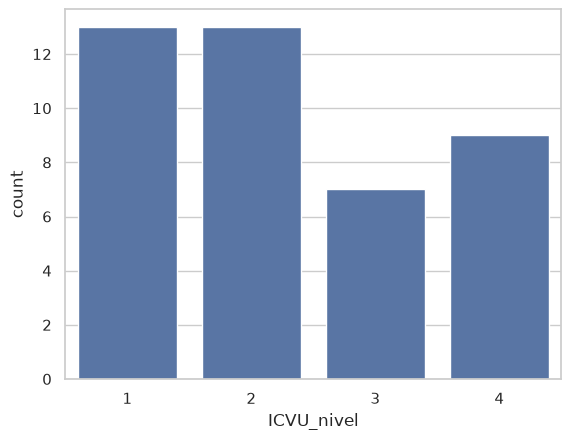

In [22]:
print(df["ICVU_nivel"].value_counts().sort_index())
sns.countplot(data=df, x="ICVU_nivel")

## 3.2 Distribuciones y sesgos

Variables con |sesgo| > 1: 31 -> 24 tras log1p
x10k_Planta_residuos      0.86
pct_area_Vertedero        0.74
x10k_Vertedero            0.71
x10k_Tren_estacion        0.64
pct_area_Suelo_desnudo    0.62
x10k_Terminal_bus         0.62
x10k_Suelo_desnudo        0.60
x10k_Metro_estacion       0.33
x10k_Metro_entrada        0.33
x10k_Museo                0.29
dtype: float64


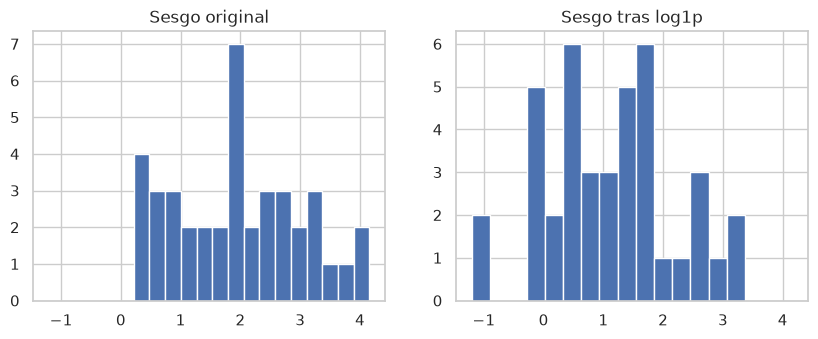

In [23]:
asim = df[FEATURES].skew()
asim_log = np.log1p(df[FEATURES]).skew()
print("Variables con |sesgo| > 1:", (asim.abs() > 1).sum(), "->", (asim_log.abs() > 1).sum(), "tras log1p")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
ax[0].hist(asim, bins=15); ax[0].set_title("Sesgo original")
ax[1].hist(asim_log, bins=15); ax[1].set_title("Sesgo tras log1p")

ceros = (df[FEATURES] == 0).mean().sort_values(ascending=False)
print(ceros.head(10).round(2))

## 3.3 Outlier por comuna

In [ ]:
L = np.log1p(df[FEATURES])
Z = (L - L.mean()) / L.std()
atipicas = (Z.abs() > 3).sum(axis=1)
print(df.assign(n_atipicas=atipicas).nlargest(8, "n_atipicas")[["comuna", "ICVU_nivel", "n_atipicas"]])

         comuna  ICVU_nivel  n_atipicas
2   Providencia           4           8
1      Vitacura           4           3
8    Huechuraba           4           3
19    Cerrillos           2           2
0    Las Condes           4           1
6      Santiago           4           1
9        Colina           3           1
10        Maipú           3           1


/tmp/ipykernel_42907/577802309.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  print(df.assign(n_atipicas=atipicas).nlargest(8, "n_atipicas")[["comuna", "ICVU_nivel", "n_atipicas"]])


## 3.4 Relación con el ICVU

<Axes: title={'center': 'Spearman con ICVU_nivel'}, xlabel='ICVU_nivel'>

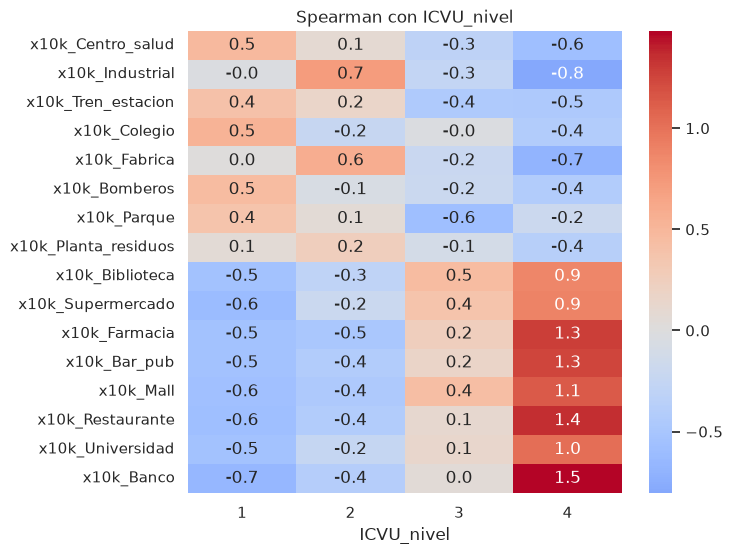

In [ ]:
corr = df[FEATURES].corrwith(df["ICVU_nivel"], method="spearman").sort_values()
top = pd.concat([corr.head(8), corr.tail(8)])
top.plot.barh(figsize=(7, 6)); plt.title("Spearman con ICVU_nivel")

# Perfil medio por nivel (estandarizado)
perfil = Z.groupby(df["ICVU_nivel"]).mean().T.loc[top.index]
sns.heatmap(perfil, cmap="coolwarm", center=0, annot=True, fmt=".1f")

## 3.5 Redundancia entre variables

3 pares con |rho| > 0.9
x10k_Metro_estacion  x10k_Metro_entrada        0.969544
x10k_Suelo_desnudo   pct_area_Suelo_desnudo    0.947153
x10k_Vertedero       pct_area_Vertedero        0.904737
dtype: float64


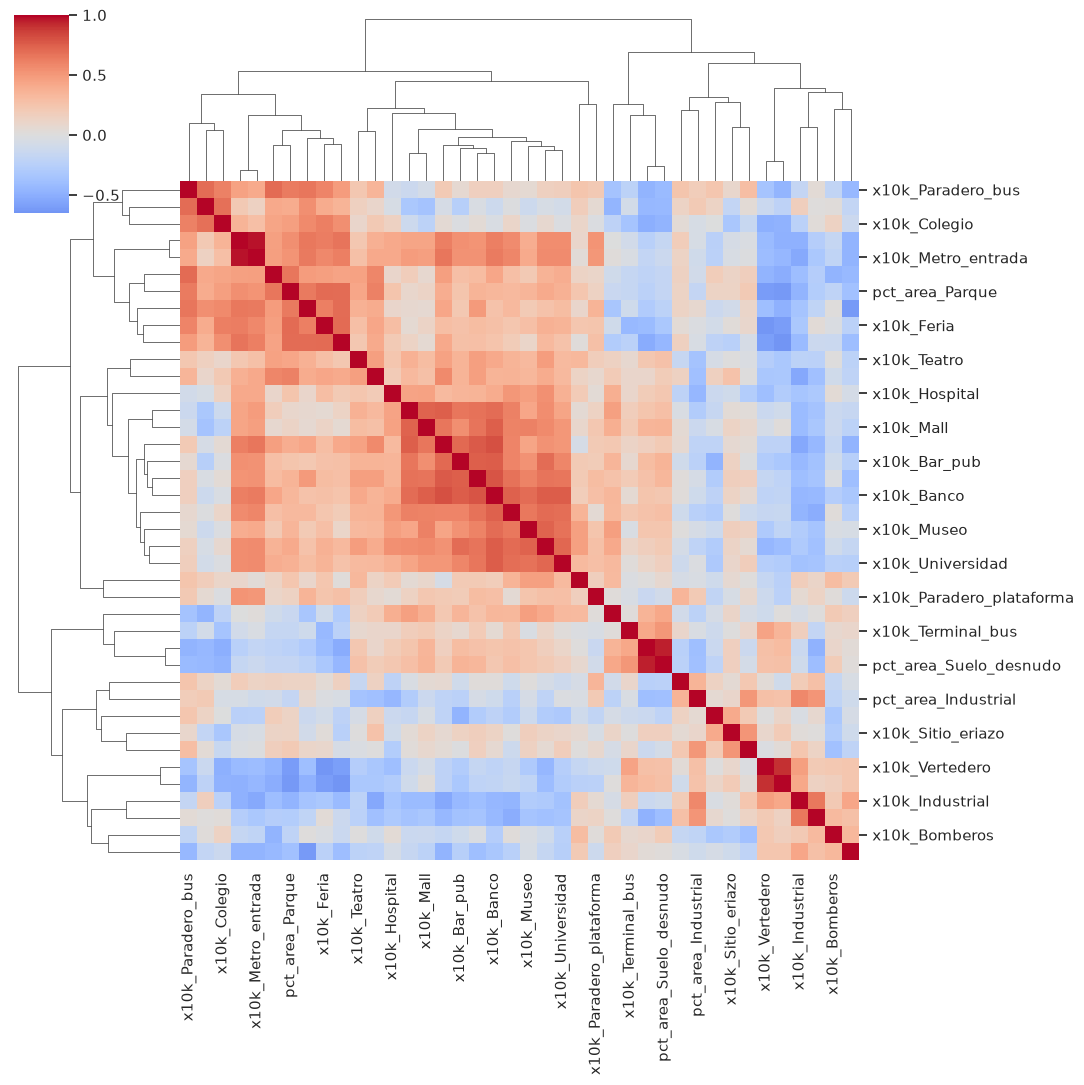

In [ ]:
C = df[FEATURES].corr(method="spearman").abs()
pares = (C.where(np.triu(np.ones(C.shape), 1).astype(bool))
          .stack().loc[lambda s: s > 0.9].sort_values(ascending=False))
print(len(pares), "pares con |rho| > 0.9")
print(pares.head(10))

sns.clustermap(df[FEATURES].corr(method="spearman"), cmap="coolwarm", center=0, figsize=(11, 11))

## 3.6 Visión global

Varianza explicada: [0.33 0.16]


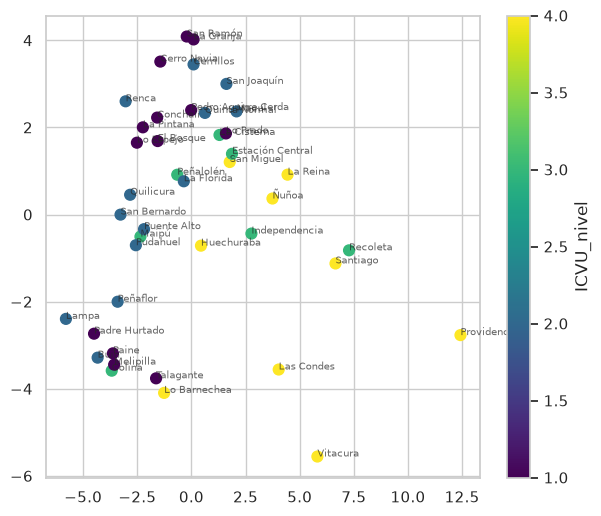

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pca = PCA(n_components=2)
P = pca.fit_transform(StandardScaler().fit_transform(L))
print("Varianza explicada:", pca.explained_variance_ratio_.round(2))

plt.figure(figsize=(7, 6))
plt.scatter(P[:, 0], P[:, 1], c=df["ICVU_nivel"], cmap="viridis", s=60)
for x, y_, n in zip(P[:, 0], P[:, 1], df["comuna"]):
    plt.annotate(n, (x, y_), fontsize=7, alpha=0.7)
plt.colorbar(label="ICVU_nivel")

In [ ]:
n_cols = [c for c in df.columns if c.startswith("n_")]
total = df[n_cols].sum(axis=1)
print(total.corr(df["ICVU_nivel"], method="spearman"))

0.4239926327992306


## 3.7 Conclusiones del EDA
- **Objetivo:** nivel más pequeño con N comunas; baseline = X%.
- **Sesgo:** log1p reduce el sesgo de A a B variables → se mantiene.
- **Outliers:** comunas atípicas: ... (se conservan / se vigilan).
- **Señal:** variables más asociadas al ICVU: ...
- **Redundancia:** grupos correlacionados: ... → candidatas a reducir.
- **Separabilidad (PCA):** los niveles ... se agrupan / se mezclan.
- **Limitación:** correlación del volumen total de OSM con el ICVU = ρ.

# 4. Modelos


## 4.1 Modelo KNN para predecir el ICVU

* Tipo: supervisado, **clasificación** ordinal (variable objetivo: nivel ICVU 2025 codificado 1 = Bajo … 4 = Alto)
* Modelo: KNN (`KNeighborsClassifier`)
* Unidad de análisis: **comuna** (una fila por comuna, generada por `data_obtain_comunas.ipynb`)



4.2 Librerías
La celda siguiente instala lo necesario en el kernel actual (solo hace falta la primera vez).

In [1]:
%pip install -q pandas numpy scikit-learn matplotlib joblib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

### 4.1.2 Parámetros

In [3]:
DEBUG = True
SEMILLA = 42

DATASET = "dataset/dataset_comunas.csv"   # salida de data_obtain_comunas.ipynb (con ICVU unido a features)

GUARDAR_MODELO = "modelo/modelo_knn_icvu_clasif.joblib"

TEST_SIZE = 0.3

### 4.1.3 Cargar dataset

In [4]:
df = pd.read_csv('dataset/processed/dataset_limpio.csv')
#df = df.drop(columns=["nivel_2025", "comuna"])
df["ICVU_nivel"] = df["ICVU_nivel"].astype(int)

print("Filas, Columnas")
print(df.shape)
print(df["ICVU_nivel"].value_counts().sort_index())   # cuántas comunas hay en cada nivel
#print(df)

Filas, Columnas
(42, 126)
ICVU_nivel
1    13
2    13
3     7
4     9
Name: count, dtype: int64


### 4.1.4 Selección de variables

In [5]:
columnas = [c for c in df.columns if c.startswith("x10k_") or c.startswith("pct_area_")]
columnas.append("hab_km2")

X = df[columnas]
y = df["ICVU_nivel"]

### 4.1.5 Modelo

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=42, stratify=y
)

### 4.1.6 Parametros del modelo
* Rellenar missing values con mediana
* Escalar StandardScaler
* Modelo KNN

In [7]:
modelo = Pipeline([
    ("imputar", SimpleImputer(strategy="median")),   # rellena datos faltantes
    ("escalar", StandardScaler()),                   # pone todas las variables en la misma escala
    ("knn", KNeighborsClassifier()),    # el clasificador
])

In [8]:
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

### 4.1.7 Metricas de evaluación

Accuracy: 0.6153846153846154
              precision    recall  f1-score   support

           1       1.00      0.75      0.86         4
           2       0.50      1.00      0.67         4
           3       0.00      0.00      0.00         2
           4       1.00      0.33      0.50         3

    accuracy                           0.62        13
   macro avg       0.62      0.52      0.51        13
weighted avg       0.69      0.62      0.58        13



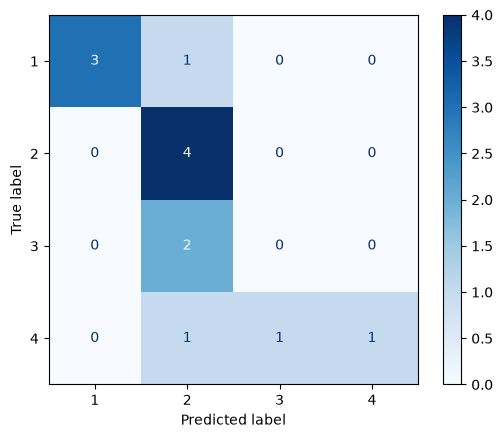

In [9]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))   # precision y recall por nivel

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")

### 4.1.8 Cross validation

In [10]:
from sklearn.model_selection import cross_val_score
cross_val_score(modelo, X, y, cv=5)

array([0.22222222, 0.55555556, 0.25      , 0.5       , 0.375     ])

## 4.2 Modelo KNN para predecir el ICVU

* Tipo: supervisado, regresión (variable objetivo: nivel ICVU 2025 codificado 1 = Bajo … 4 = Alto, porque la CChC ya no publica el puntaje numérico; la predicción se redondea al nivel más cercano)
* Modelo: KNN (`KNeighborsRegressor`)
* Unidad de análisis: **comuna** (una fila por comuna, generada por `data_obtain_comunas.ipynb`)

v1.0 · 18-10-2026

**Correcciones respecto de la versión v0.0**

| Problema | Corrección |
|---|---|
| `dataset_src = "./"` (carpeta, no archivo) | Apunta a `dataset_comunas.csv` y verifica que exista y tenga ICVU |
| `X` incluía texto (nombre de comuna) → `StandardScaler` falla | Solo columnas numéricas, elegidas por grupo (`FEATURE_SET`) |
| NaN → KNN falla | `SimpleImputer` dentro del Pipeline |
| Conteos muy sesgados (pocas comunas concentran todo) | `log1p` dentro del Pipeline |
| Una sola separación 80/20 con ~30 comunas = ~7 de prueba, resultado muy inestable | **Validación cruzada anidada repetida** (5 × 10): la búsqueda de K se hace dentro de cada pliegue, sin mirar los datos de prueba |
| Sin referencia | Se compara contra `DummyRegressor` (predice siempre el promedio) |
| `K` hasta 20 aunque haya pocas filas | El rango de K se ajusta al tamaño del entrenamiento |
| Import duplicado; `pip install --upgrade` (podía romper el entorno) | Import eliminado; instalación simple sin `--upgrade` |

### 4.2.1 Librerías
La celda siguiente instala lo necesario en el kernel actual (solo hace falta la primera vez).

In [11]:
%pip install -q pandas numpy scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.


In [12]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import KFold, RepeatedKFold, GridSearchCV, cross_val_predict
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_squared_error, root_mean_squared_error, mean_absolute_error,
                             mean_absolute_percentage_error, r2_score)

### 4.2.2 Parámetros

In [13]:
DEBUG = True
SEMILLA = 42

DATASET = "dataset/processed/dataset_limpio.csv"   # salida de data_obtain_comunas.ipynb (con ICVU unido)
# La CChC ya no publica el puntaje numérico, solo el nivel -> objetivo ordinal 1 (Bajo) .. 4 (Alto).
# Si consigues el puntaje numérico, agrégalo como columna ICVU y usa OBJETIVO = "ICVU".
OBJETIVO = "ICVU_nivel"
ES_ORDINAL = OBJETIVO == "ICVU_nivel"   # agrega la métrica "acierto de nivel"
ID_COLS = ["comuna"]

# Qué variables usa el modelo. KNN empeora con muchas variables (todas pesan igual en la distancia),
# así que por defecto se usan los totales por categoría + % de área.
#   "categoria" -> dens_cat_* + pct_area_*            (~12 variables)
#   "tipo"      -> dens_<tipo> + pct_area_*           (~39 variables)
#   "habitante" -> x10k_cat_* + pct_area_* + hab_km2  (por 10.000 hab; requiere poblacion_comunas.csv)
#   "habitante_tipo" -> x10k_<tipo> + pct_area_* + hab_km2
#   o una lista explícita de columnas
# Elegido "habitante_tipo": con los datos reales (42 comunas, CV 5x10) fue el de menor error
#   habitante_tipo RMSE 0.86 · tipo 0.98 · habitante 1.07 · categoria 1.09 · baseline 1.14
# Además, las variables por habitante evitan el sesgo de las comunas con mucha superficie
# rural (Lo Barnechea, Colina, Melipilla...), cuyas densidades por km² salen artificialmente bajas.
FEATURE_SET = "habitante_tipo"

USAR_LOG = True        # log1p a las variables (son densidades >= 0 y muy sesgadas)

# Validación cruzada
CV_EXTERNA_PLIEGUES = 5
CV_EXTERNA_REPETICIONES = 10
CV_INTERNA_PLIEGUES = 5
K_MAX = 20

GUARDAR_MODELO = "modelo/modelo_knn_icvu.joblib"

### 4.2.3 Cargar dataset

In [14]:
if not Path(DATASET).exists():
    raise FileNotFoundError(f"No existe {DATASET}. Ejecutar antes data_obtain_comunas.ipynb")

df = pd.read_csv(DATASET)
if OBJETIVO not in df.columns:
    raise KeyError(f"El dataset no tiene la columna {OBJETIVO}. Completar icvu_comunas.csv "
                   f"y volver a ejecutar la sección 'Unir ICVU' de data_obtain_comunas.ipynb")

sin_y = df[OBJETIVO].isna()
if sin_y.any():
    print("Se excluyen (sin ICVU):", df.loc[sin_y, "comuna"].tolist())
df = df[~sin_y].reset_index(drop=True)

if DEBUG:
    print(df.shape)
    print(df[OBJETIVO].describe())

(42, 126)
count    42.000000
mean      2.285714
std       1.132356
min       1.000000
25%       1.000000
50%       2.000000
75%       3.000000
max       4.000000
Name: ICVU_nivel, dtype: float64


### 4.2.4 Selección de variables

In [15]:
def seleccionar_features(df, feature_set):
    if isinstance(feature_set, (list, tuple)):
        cols = list(feature_set)
    else:
        prefijos = {"categoria": ["dens_cat_"],
                    "tipo": ["dens_"],
                    "habitante": ["x10k_cat_"],
                    "habitante_tipo": ["x10k_"]}[feature_set]
        cols = [c for c in df.columns if any(c.startswith(p) for p in prefijos)]
        if feature_set == "tipo":
            cols = [c for c in cols if not c.startswith("dens_cat_")]
        if feature_set == "habitante_tipo":
            cols = [c for c in cols if not c.startswith("x10k_cat_")]
        cols += [c for c in df.columns if c.startswith("pct_area_")]
        if feature_set.startswith("habitante"):
            cols += ["hab_km2"]
        if not cols:
            raise ValueError(f"No hay columnas para FEATURE_SET={feature_set!r} "
                             f"(¿falta poblacion_comunas.csv para las variables por habitante?)")
    cols = [c for c in cols if c not in ID_COLS + [OBJETIVO]
            and pd.api.types.is_numeric_dtype(df[c])]
    # Variables constantes (p. ej. 0 en todas las comunas) no aportan a la distancia
    constantes = [c for c in cols if df[c].nunique(dropna=True) <= 1]
    if constantes and DEBUG:
        print("Se descartan por constantes:", constantes)
    return [c for c in cols if c not in constantes]


features = seleccionar_features(df, FEATURE_SET)
X = df[features]
y = df[OBJETIVO]
n = len(df)

print(f"{n} comunas, {len(features)} variables")
if n < 10:
    raise ValueError("Muy pocas comunas para entrenar y evaluar. Agregar comunas en data_obtain_comunas.ipynb")
if DEBUG:
    print(features)
    print(X.isna().sum()[X.isna().sum() > 0])

42 comunas, 40 variables
['x10k_Hospital', 'x10k_Clinica', 'x10k_Centro_salud', 'x10k_Consultorio', 'x10k_Farmacia', 'x10k_Parque', 'x10k_Mall', 'x10k_Restaurante', 'x10k_Museo', 'x10k_Biblioteca', 'x10k_Teatro', 'x10k_Bomberos', 'x10k_Comisaria', 'x10k_Colegio', 'x10k_Jardin_infantil', 'x10k_Universidad', 'x10k_Supermercado', 'x10k_Banco', 'x10k_Feria', 'x10k_Almacen', 'x10k_Metro_estacion', 'x10k_Tren_estacion', 'x10k_Metro_entrada', 'x10k_Paradero_bus', 'x10k_Paradero_plataforma', 'x10k_Terminal_bus', 'x10k_Vertedero', 'x10k_Planta_residuos', 'x10k_Industrial', 'x10k_Fabrica', 'x10k_Botilleria', 'x10k_Bar_pub', 'x10k_Sitio_eriazo', 'x10k_Suelo_desnudo', 'pct_area_Parque', 'pct_area_Industrial', 'pct_area_Vertedero', 'pct_area_Sitio_eriazo', 'pct_area_Suelo_desnudo', 'hab_km2']
Series([], dtype: int64)


### 4.2.5

In [16]:
def crear_pipeline():
    pasos = []
    if USAR_LOG:
        pasos.append(("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")))
    pasos += [
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),   # necesario para KNN
        ("knn", KNeighborsRegressor()),
    ]
    return Pipeline(pasos)


# K no puede superar el tamaño del entrenamiento dentro de la CV interna
n_train_interno = int(n * (1 - 1 / CV_EXTERNA_PLIEGUES) * (1 - 1 / CV_INTERNA_PLIEGUES))
k_max = max(1, min(K_MAX, n_train_interno))

param_grid = {
    "knn__n_neighbors": list(range(1, k_max + 1)),
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],    # Manhattan vs Euclidiana
}


def crear_busqueda():
    return GridSearchCV(crear_pipeline(), param_grid,
                        cv=KFold(CV_INTERNA_PLIEGUES, shuffle=True, random_state=SEMILLA),
                        scoring="neg_root_mean_squared_error", n_jobs=-1)

print(f"K entre 1 y {k_max}")

K entre 1 y 20


### 4.2.6 Evaluación: validación cruzada anidada repetida

En cada uno de los 5 × 10 = 50 pliegues externos: se busca el mejor K **solo con el entrenamiento** del pliegue y se mide el error en las comunas que quedaron fuera. Así la métrica no está inflada por haber elegido K mirando los datos de prueba.

In [17]:
def a_nivel(pred):
    # predicción continua -> nivel 1..4 más cercano
    return np.clip(np.rint(pred), 1, 4)


def metricas(y_true, y_pred):
    m = {
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }
    if ES_ORDINAL:
        dif = np.abs(a_nivel(y_pred) - np.asarray(y_true))
        m["Acierto_nivel"] = np.mean(dif == 0)       # nivel exacto
        m["Acierto_±1"] = np.mean(dif <= 1)          # a lo más un nivel de diferencia
    return m


cv_ext = RepeatedKFold(n_splits=CV_EXTERNA_PLIEGUES, n_repeats=CV_EXTERNA_REPETICIONES,
                       random_state=SEMILLA)
filas, mejores = [], []
for tr, te in cv_ext.split(X):
    busq = crear_busqueda().fit(X.iloc[tr], y.iloc[tr])
    base = DummyRegressor(strategy="mean").fit(X.iloc[tr], y.iloc[tr])
    filas.append({"modelo": "KNN", **metricas(y.iloc[te], busq.predict(X.iloc[te]))})
    filas.append({"modelo": "Baseline (promedio)", **metricas(y.iloc[te], base.predict(X.iloc[te]))})
    mejores.append(busq.best_params_)

res = pd.DataFrame(filas)
resumen = res.groupby("modelo").agg(["mean", "std"]).round(3)
print(resumen.to_string())

print("\nParámetros elegidos con más frecuencia en los pliegues:")
print(pd.DataFrame(mejores).value_counts().head(5).to_string())

                       MSE          RMSE          MAE          MAPE            R2        Acierto_nivel        Acierto_±1       
                      mean    std   mean   std   mean    std   mean    std   mean    std          mean    std       mean    std
modelo                                                                                                                         
Baseline (promedio)  1.326  0.425  1.135  0.20  1.000  0.210  0.591  0.205 -0.415  1.428         0.304  0.155      0.769  0.146
KNN                  0.782  0.348  0.864  0.19  0.693  0.164  0.394  0.139  0.130  0.819         0.411  0.165      0.917  0.081

Parámetros elegidos con más frecuencia en los pliegues:
knn__n_neighbors  knn__p  knn__weights
2                 1       distance        11
6                 2       distance         5
3                 1       distance         5
2                 1       uniform          4
3                 2       distance         3


### 4.2.7 Predicción fuera de muestra por comuna
Cada comuna se predice con un modelo que no la vio al entrenar.

Matriz real (filas) vs predicho (columnas), 1=Bajo .. 4=Alto:
nivel_pred  1  2  3  4
ICVU_real             
1           3  8  2  0
2           3  7  3  0
3           0  4  2  1
4           0  3  4  2 

             comuna  ICVU_real  ICVU_pred  error  nivel_pred
         San Miguel          4       1.84  -2.16           2
           Lo Prado          1       3.01   2.01           3
          Talagante          1       2.80   1.80           3
       Lo Barnechea          4       2.49  -1.51           2
         Huechuraba          4       2.49  -1.51           2
      Padre Hurtado          1       2.18   1.18           2
          Peñalolén          3       1.99  -1.01           2
           Conchalí          1       2.00   1.00           2
          Cerrillos          2       1.00  -1.00           1
          Melipilla          1       1.99   0.99           2
              Ñuñoa          4       3.01  -0.99           3
             Colina          3       2.04  -0.96           2
     

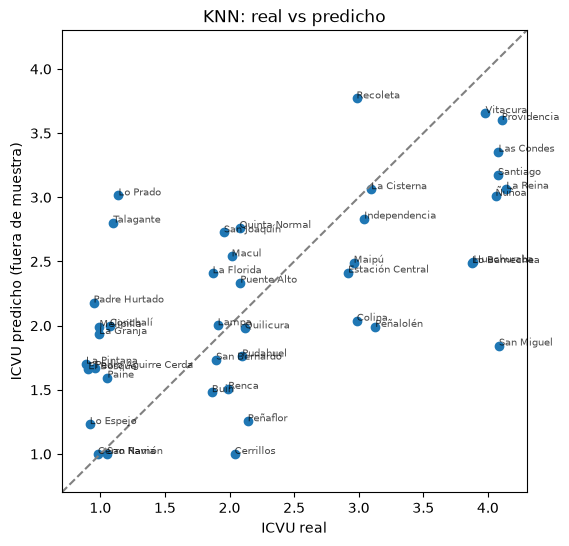

In [18]:
y_oof = cross_val_predict(crear_busqueda(), X, y,
                          cv=KFold(CV_EXTERNA_PLIEGUES, shuffle=True, random_state=SEMILLA))
pred = df[ID_COLS].assign(ICVU_real=y, ICVU_pred=y_oof, error=y_oof - y)
if ES_ORDINAL:
    pred["nivel_pred"] = a_nivel(y_oof).astype(int)
    print("Matriz real (filas) vs predicho (columnas), 1=Bajo .. 4=Alto:")
    print(pd.crosstab(pred["ICVU_real"], pred["nivel_pred"]), "\n")
print(pred.sort_values("error", key=abs, ascending=False).round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 6))
# pequeño desplazamiento horizontal para que no se tapen las comunas del mismo nivel
x_plot = y + (np.random.default_rng(SEMILLA).uniform(-0.15, 0.15, len(y)) if ES_ORDINAL else 0)
ax.scatter(x_plot, y_oof)
for xi, (_, r) in zip(x_plot, pred.iterrows()):
    ax.annotate(r[ID_COLS[0]], (xi, r.ICVU_pred), fontsize=7, alpha=0.7)
margen = 0.1 * (y.max() - y.min())
lims = [min(y.min(), y_oof.min()) - margen, max(y.max(), y_oof.max()) + margen]
ax.plot(lims, lims, linestyle="--", color="gray")
ax.set(xlim=lims, ylim=lims, xlabel="ICVU real", ylabel="ICVU predicho (fuera de muestra)",
       title="KNN: real vs predicho")
plt.show()

### 4.2.8 Modelo final (entrenado con todas las comunas)

In [19]:
final = crear_busqueda().fit(X, y)
print("Mejores parámetros:", final.best_params_)
print(f"RMSE CV interno: {-final.best_score_:.3f}")

if GUARDAR_MODELO:
    joblib.dump({"modelo": final.best_estimator_, "features": features}, GUARDAR_MODELO)
    print("Guardado en", GUARDAR_MODELO)

Mejores parámetros: {'knn__n_neighbors': 2, 'knn__p': 1, 'knn__weights': 'distance'}
RMSE CV interno: 0.768
Guardado en modelo/modelo_knn_icvu.joblib


### 4.2.9 Comparar conjuntos de variables

In [20]:
if DEBUG:
    opciones = ["categoria", "tipo"] + (["habitante", "habitante_tipo"]
                                        if any(c.startswith("x10k_") for c in df.columns) else [])
    comp = []
    for fs in opciones:
        cols = seleccionar_features(df, fs)
        Xi = df[cols]
        rmse = []
        for tr, te in RepeatedKFold(n_splits=CV_EXTERNA_PLIEGUES, n_repeats=3, random_state=SEMILLA).split(Xi):
            b = crear_busqueda().fit(Xi.iloc[tr], y.iloc[tr])
            rmse.append(root_mean_squared_error(y.iloc[te], b.predict(Xi.iloc[te])))
        comp.append({"FEATURE_SET": fs, "n_variables": len(cols), "RMSE_medio": np.mean(rmse)})
    print(pd.DataFrame(comp).round(3).to_string(index=False))

   FEATURE_SET  n_variables  RMSE_medio
     categoria           12       1.142
          tipo           39       0.969
     habitante           13       1.096
habitante_tipo           40       0.865
